# Comparaison avec les images de damier d'OpenCV

In [ ]:
import os, glob, urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

CV_DIR = "images_opencv" 
MY_CALIB = "results/calib.npz"
PATTERN_CV = (9, 6)

# mêmes réglages que pour mes photos
FLAGS = cv2.CALIB_FIX_K3 | cv2.CALIB_ZERO_TANGENT_DIST
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## 1. Téléchargement des images d'OpenCV

In [2]:
os.makedirs(CV_DIR, exist_ok=True)
base = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
for i in [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14]:      # left10 n'existe pas
    fn = f"left{i:02d}.jpg"
    path = os.path.join(CV_DIR, fn)
    if not os.path.exists(path):
        urllib.request.urlretrieve(base + fn, path)

files_cv = sorted(glob.glob(os.path.join(CV_DIR, "left*.jpg")))
print(len(files_cv), "images")

13 images


## 2. Détection des coins

Images utilisées : 13 / 13  | taille : (640, 480)


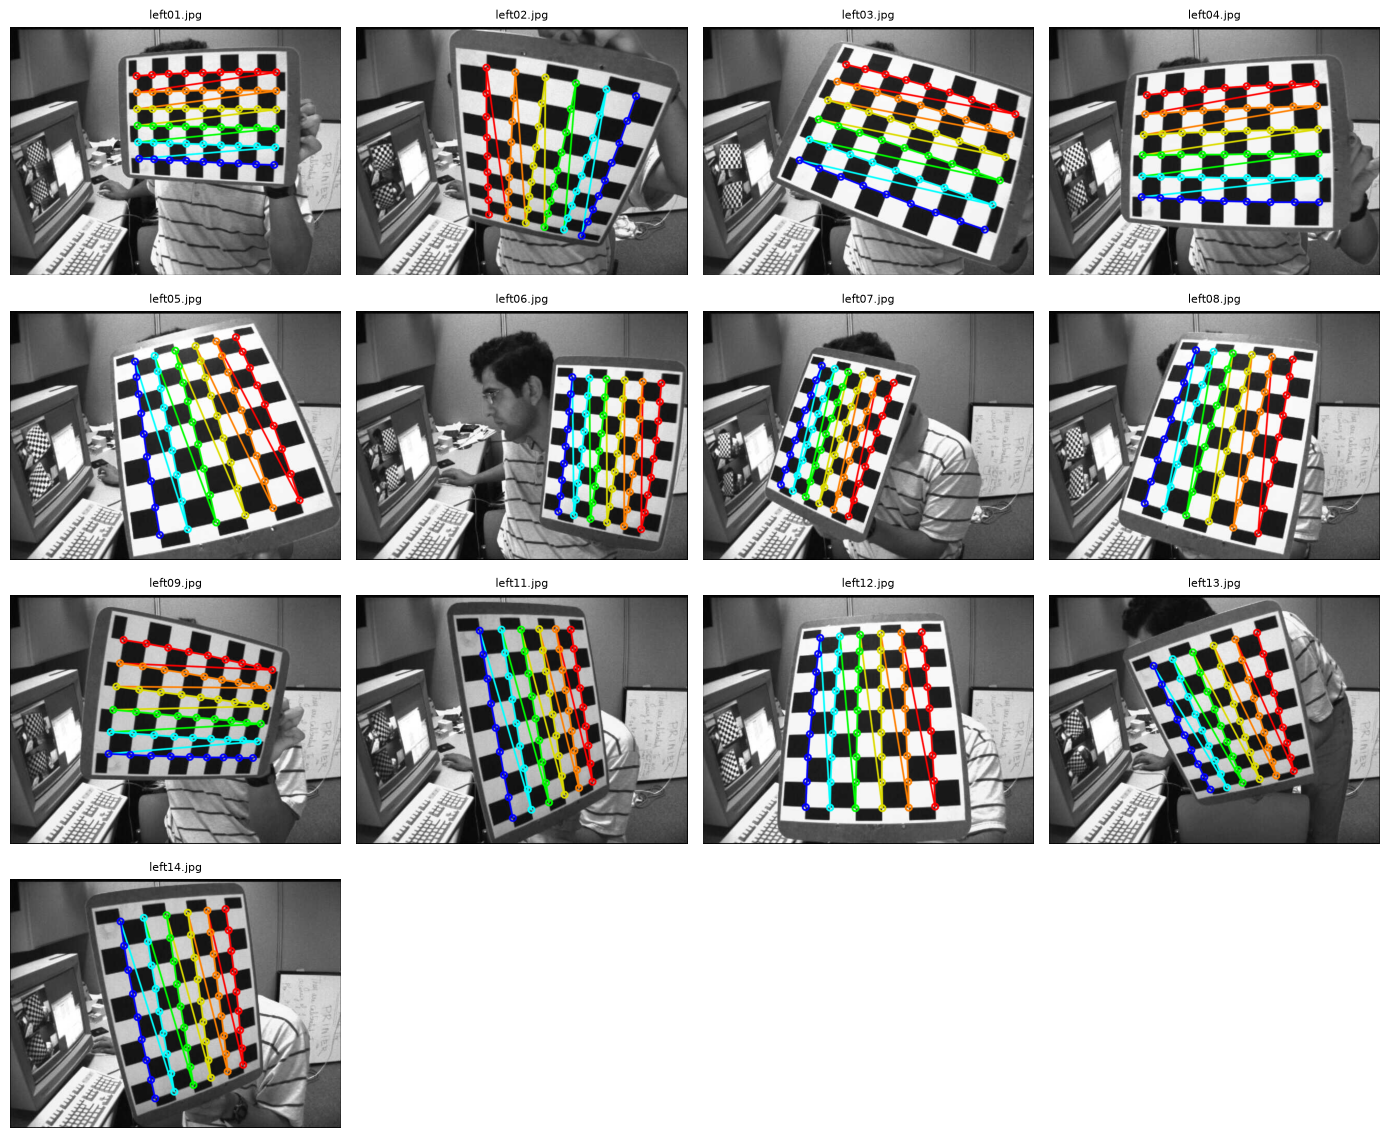

In [ ]:
def draw_corners_thick(img, pattern, corners, th=2):
    vis = img.copy()
    cols, rows = pattern
    pts = np.round(corners.reshape(-1, 2)).astype(int)
    palette = [(0, 0, 255), (0, 128, 255), (0, 220, 220), (0, 255, 0),
               (255, 255, 0), (255, 0, 0), (255, 0, 255)]
    for r in range(rows):
        color = palette[r % len(palette)]
        row = pts[r * cols:(r + 1) * cols]
        for i, p in enumerate(row):
            if i > 0:
                cv2.line(vis, tuple(row[i - 1]), tuple(p), color, th, cv2.LINE_AA)
            cv2.circle(vis, tuple(p), 3 * th, color, th, cv2.LINE_AA)
        if r + 1 < rows:
            cv2.line(vis, tuple(row[-1]), tuple(pts[(r + 1) * cols]), color, th, cv2.LINE_AA)
    return vis


objp = np.zeros((PATTERN_CV[0] * PATTERN_CV[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN_CV[0], 0:PATTERN_CV[1]].T.reshape(-1, 2)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
flags_cb = cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE

objpoints, imgpoints, used_cv, previews = [], [], [], []
for path in files_cv:
    img = cv2.imread(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    found, corners = cv2.findChessboardCorners(gray, PATTERN_CV, flags_cb)
    if not found:
        print("[NON DÉTECTÉ]", os.path.basename(path))
        continue
    corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), criteria)
    objpoints.append(objp)
    imgpoints.append(corners)
    used_cv.append(os.path.basename(path))
    previews.append((os.path.basename(path), draw_corners_thick(img, PATTERN_CV, corners)))

size_cv = (gray.shape[1], gray.shape[0])
print(f"Images utilisées : {len(used_cv)} / {len(files_cv)}  | taille : {size_cv}")

ncols = 4
nrows = int(np.ceil(len(previews) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.9 * nrows))
for ax in axes.ravel():
    ax.axis("off")
for ax, (name, im) in zip(axes.ravel(), previews):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=8)
plt.tight_layout()
plt.show()

## 3. Calibration et erreur de reprojection

In [4]:
rms_cv, K_cv, dist_cv, rvecs, tvecs = cv2.calibrateCamera(
    objpoints, imgpoints, size_cv, None, None, flags=FLAGS)

err_cv = []
for op, ip, rv, tv in zip(objpoints, imgpoints, rvecs, tvecs):
    proj, _ = cv2.projectPoints(op, rv, tv, K_cv, dist_cv)
    err_cv.append(np.mean(np.linalg.norm(proj.reshape(-1, 2) - ip.reshape(-1, 2), axis=1)))
err_cv = np.array(err_cv)

print(f"RMS = {rms_cv:.3f} px | erreur moyenne = {err_cv.mean():.3f} px")
print("K =\n", np.round(K_cv, 2))
print("Distorsion (k1, k2, p1, p2, k3) :", np.round(dist_cv.ravel(), 4))

RMS = 0.418 px | erreur moyenne = 0.242 px
K =
 [[536.46   0.   342.39]
 [  0.   536.74 234.33]
 [  0.     0.     1.  ]]
Distorsion (k1, k2, p1, p2, k3) : [-0.2809  0.0784  0.      0.      0.    ]


## 4. Comparaison avec ma calibration

In [7]:
if os.path.exists(MY_CALIB):
    d = np.load(MY_CALIB)
    my = dict(n=len(d["used_images"]), size=tuple(int(v) for v in d["image_size"]),
              rms=float(d["rms"]), mean=float(np.mean(d["errors"])))
else:   # valeurs de mon notebook principal, si calib.npz n'est pas là
    my = dict(n=11, size=(3072, 4080), rms=6.594, mean=6.505)

rows = [
    ("OPPO A78, damier au crayon", my["n"], my["size"], my["rms"], my["mean"]),
    ("OpenCV, damier imprimé", len(used_cv), size_cv, rms_cv, err_cv.mean()),
]

print(f"{'Jeu d images':<28} {'images':>6} {'taille':>11} {'RMS (px)':>9} {'moy. (px)':>9} {'RMS/diag':>9}")
for name, n, s, r, m in rows:
    diag = np.hypot(*s)
    print(f"{name:<28} {n:>6} {s[0]:>5}x{s[1]:<5} {r:>9.3f} {m:>9.3f} {100 * r / diag:>8.3f}%")

ratio = (rows[0][3] / np.hypot(*rows[0][2])) / (rows[1][3] / np.hypot(*rows[1][2]))

Jeu d images                 images      taille  RMS (px) moy. (px)  RMS/diag
OPPO A78, damier au crayon       11  3072x4080      6.594     6.505    0.129%
OpenCV, damier imprimé           13   640x480       0.418     0.242    0.052%


Rapportée à la taille de l'image, mon erreur est 2.5 fois plus grande